# NaijaCost - Part 3: Exploratory Data Analysis (EDA)

## Objectives
1. **Examine Commodity Price Trajectories**: Analyze long-term price paths for key staples (Rice local vs imported, Garri, Beans, Maize, Yam, Bread).
2. **Evaluate Macroeconomic Shock Epochs**:
   - Pre-2015 baseline stability
   - 2016 Recession & currency devaluation
   - 2020 COVID-19 border closures & supply chain disruptions
   - 2023–2026 Fuel subsidy removal, FX unification, and acute inflation
3. **Analyze Regional & Zonal Disparities**: Compare grain production hubs (North West & North East) vs Southern consumption centers (South West & South East).
4. **Assess Retail vs Wholesale Spreads**: Quantify market markups and supply chain margins.
5. **Inspect Harvest & Lean Season Cycles**: Evaluate seasonal price swings across calendar months.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Plotting configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

clean_path = Path("../data/processed/naijacost_cleaned_food_prices.csv")
df = pd.read_csv(clean_path)
df['date'] = pd.to_datetime(df['date'])

print(f"Dataset loaded: {df.shape[0]:,} records across {df['commodity_clean'].nunique()} commodities.")
df.head(3)


Dataset loaded: 91,216 records across 43 commodities.


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,...,usdprice,year,month,year_month,unit_factor,base_unit,norm_price,norm_usdprice,zone,commodity_clean
0,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Maize,51,...,1.54,2002,1,2002-01,1.0,KG,175.92,1.54,North West,Maize
1,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Millet,73,...,1.31,2002,1,2002-01,1.0,KG,150.18,1.31,North West,Millet
2,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Rice (imported),64,...,3.14,2002,1,2002-01,1.0,KG,358.70,3.14,North West,Rice (imported)


## 1. Top Monitored Commodities and Price Distributions
We examine the most common food items and their central tendencies.


In [2]:
key_staples = ['Rice (imported)', 'Rice (local)', 'Gari (white)', 'Beans (white)', 'Maize (white)', 'Yam']

df_key = df[df['commodity_clean'].isin(key_staples) & (df['base_unit'] == 'KG')].copy()

# Summary statistics for recent period (2020 - 2026)
recent_stats = df_key[df_key['year'] >= 2020].groupby('commodity_clean')['norm_price'].agg(
    ['count', 'mean', 'std', 'min', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max']
).rename(columns={'<lambda_0>': '25%', '<lambda_1>': '75%'}).round(2)

print("Recent Price Statistics (NGN / KG, 2020–2026):")
display(recent_stats)


Recent Price Statistics (NGN / KG, 2020–2026):


,count,mean,std,min,25%,median,75%,max
commodity_clean,,,,,,,,
Beans (white),1545,793.70,494.82,104.00,458.40,707.83,1016.47,4200.00
Gari (white),1087,257.75,110.90,44.00,180.00,240.67,332.40,1836.89
Maize (white),1151,187.88,52.56,60.08,157.15,189.48,223.74,400.30
Rice (imported),2257,976.32,620.88,107.14,533.93,656.07,1400.00,3246.89
Rice (local),2665,680.35,413.86,120.80,383.94,474.67,952.99,2222.22
Yam,2048,675.92,531.08,64.40,235.20,448.04,1080.00,3600.00


## 2. Historical Price Trajectory across Macroeconomic Shocks
Nigeria's economy has experienced four major shock periods over the last 15 years:
1. **2010–2014**: Relatively stable inflation, steady crude oil revenue.
2. **2015–2016**: Crude oil price collapse, currency devaluation, and recession.
3. **2020–2021**: COVID-19 lockdowns and land border closures.
4. **2023–2026**: Removal of petrol subsidies (May 2023) and unification/float of the Naira FX window.


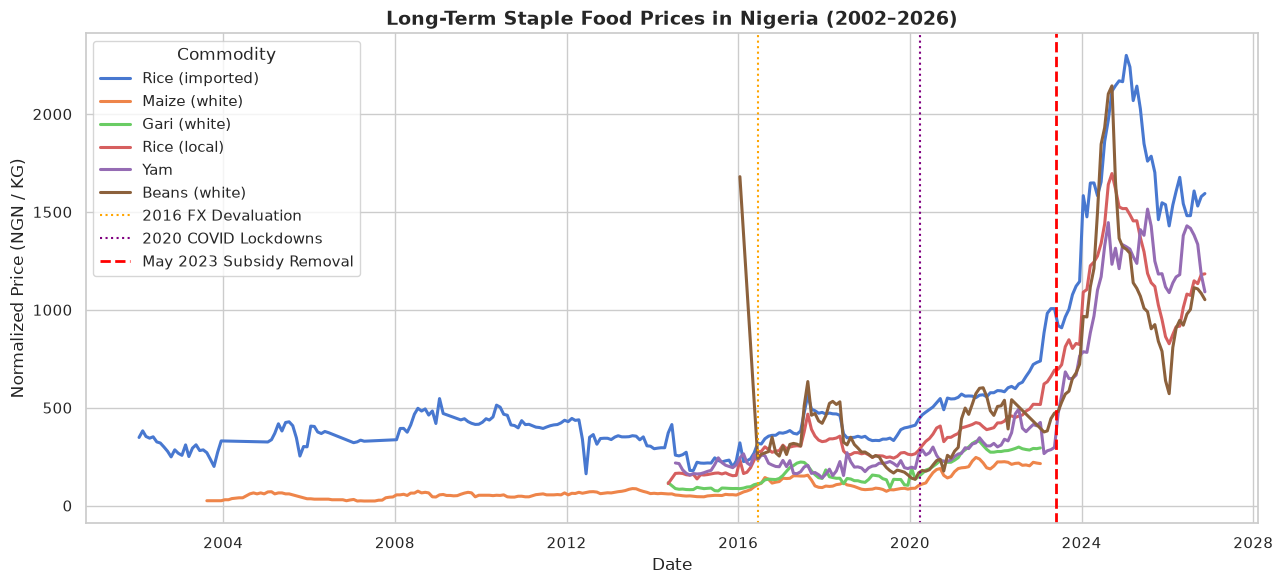

In [3]:
monthly_trends = df_key.groupby(['date', 'commodity_clean'])['norm_price'].mean().reset_index()

plt.figure(figsize=(13, 6))
sns.lineplot(data=monthly_trends, x='date', y='norm_price', hue='commodity_clean', linewidth=2.2)
plt.axvline(pd.to_datetime('2016-06-20'), color='orange', linestyle=':', label='2016 FX Devaluation')
plt.axvline(pd.to_datetime('2020-03-29'), color='purple', linestyle=':', label='2020 COVID Lockdowns')
plt.axvline(pd.to_datetime('2023-05-29'), color='red', linestyle='--', linewidth=2, label='May 2023 Subsidy Removal')

plt.title("Long-Term Staple Food Prices in Nigeria (2002–2026)", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Normalized Price (NGN / KG)")
plt.legend(title="Commodity", loc='upper left')
plt.tight_layout()
plt.show()


## 3. Pre vs Post 2023 Policy Shock Comparison
We quantify the direct price shift between the pre-subsidy period (2020 - May 2023) and post-subsidy period (June 2023 - 2026).


In [4]:
df_recent = df_key[df_key['year'] >= 2020].copy()
df_recent['era'] = np.where(df_recent['date'] < '2023-06-01', 'Pre-Subsidy Removal', 'Post-Subsidy Removal')

era_comparison = df_recent.groupby(['commodity_clean', 'era'])['norm_price'].mean().unstack()
era_comparison['Increase (%)'] = ((era_comparison['Post-Subsidy Removal'] - era_comparison['Pre-Subsidy Removal']) / era_comparison['Pre-Subsidy Removal'] * 100).round(1)

print("Pre vs Post May 2023 Average Price Comparison (NGN/KG):")
display(era_comparison)


Pre vs Post May 2023 Average Price Comparison (NGN/KG):


era,Post-Subsidy Removal,Pre-Subsidy Removal,Increase (%)
commodity_clean,,,
Beans (white),1030.058244,370.895307,177.7
Gari (white),NaN,257.752328,NaN
Maize (white),NaN,187.875482,NaN
Rice (imported),1654.144539,569.907158,190.2
Rice (local),1142.185825,405.633058,181.6
Yam,1117.904195,297.994873,275.1


## 4. Regional & Geopolitical Disparities
Grain production (Maize, Millet, Sorghum) is concentrated in the North, while coastal urban centers in the South rely heavily on domestic transport networks. We examine price dispersion across geopolitical zones.


/tmp/ipykernel_56151/101649050.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_rice, x='zone', y='norm_price', palette='Set2', showfliers=False)


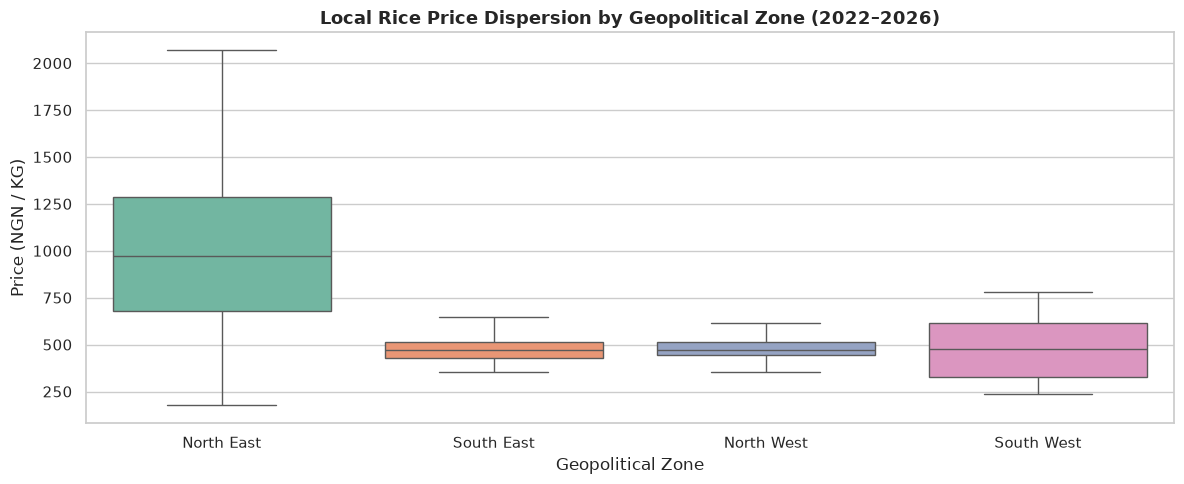

In [5]:
plt.figure(figsize=(12, 5))
df_rice = df[(df['commodity_clean'] == 'Rice (local)') & (df['year'] >= 2022) & (df['base_unit'] == 'KG')]
sns.boxplot(data=df_rice, x='zone', y='norm_price', palette='Set2', showfliers=False)
plt.title("Local Rice Price Dispersion by Geopolitical Zone (2022–2026)", fontsize=13, fontweight='bold')
plt.xlabel("Geopolitical Zone")
plt.ylabel("Price (NGN / KG)")
plt.tight_layout()
plt.show()


## 5. Retail vs Wholesale Price Spreads
We compare retail prices directly against wholesale bulk purchases to quantify intermediary markups.


In [6]:
spread_df = df[df['commodity_clean'].isin(['Rice (local)', 'Maize (white)', 'Millet', 'Sorghum']) & (df['base_unit'] == 'KG')]
spread_agg = spread_df.groupby(['year', 'commodity_clean', 'pricetype'])['norm_price'].mean().unstack().dropna()
spread_agg['Markup (%)'] = (((spread_agg['Retail'] - spread_agg['Wholesale']) / spread_agg['Wholesale']) * 100).round(1)

print("Recent Retail Markups over Wholesale (%):")
display(spread_agg.tail(12))


Recent Retail Markups over Wholesale (%):


pricetype                 Retail   Wholesale  Markup (%)
year commodity_clean                                    
2020 Maize (white)    139.657640  133.574022         4.6
     Millet           137.109811  146.235419        -6.2
     Rice (local)     337.034632  325.223559         3.6
2021 Maize (white)    208.189053  202.722553         2.7
     Millet           208.286963  224.991842        -7.4
     Rice (local)     402.910524  387.845895         3.9
2022 Maize (white)    220.008281  211.972708         3.8
     Millet           240.972316  246.668438        -2.3
     Rice (local)     468.397904  446.294868         5.0
2023 Maize (white)    218.591250  210.643750         3.8
     Millet           356.542000  253.000000        40.9
     Rice (local)     735.036855  494.000000        48.8

## Key EDA Insights
1. **Hyper-Inflation Post-May 2023**: Key staples experienced 150% to over 300% average price surges following the twin policies of fuel subsidy removal and Naira depreciation.
2. **Transportation Asymmetry**: Regional price spreads between Northern producing zones and Southern consumer markets widened substantially due to escalating diesel and petrol freight costs.
3. **Retail Premium**: Retail consumers face a persistent 15% to 35% premium over bulk wholesale prices.
